In [51]:
#1. Install/import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import LinearSVC
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,ConfusionMatrixDisplay,
    classification_report,
    roc_auc_score,
    roc_curve
)

from sklearn.model_selection import (
    StratifiedKFold, #Creates folds while preserving the churn/non-churn proportion as closely as possible.
    GridSearchCV, # Tests every specified combination of hyperparameters.
    RandomizedSearchCV #Tests a chosen number of combinations sampled from the search space.
)


In [52]:
#2. Load the CSV
df = pd.read_csv("customer_churn_classification_50k.csv")
df.head()

,customer_id,age,gender,geography,account_type,education,employment,marital_status,income,credit_score,...,is_active,estimated_salary,monthly_spend,transactions_last_3m,support_tickets,late_payments,web_logins,satisfaction_score,days_since_last_login,churn
0,1001641,22.0,Female,Chennai,Savings,Postgraduate,Salaried,Divorced,34084.02,484.0,...,0,128158.61,951.87,12,1.0,1,9,7.0,32,1
1,1025699,52.0,Female,Hyderabad,Current,Graduate,Self-employed,Single,52569.17,646.0,...,1,63379.96,2651.35,13,1.0,1,10,3.0,4,0
2,1032225,59.0,Male,Mumbai,Savings,High School,Self-employed,Married,65160.41,596.0,...,1,12334.52,1364.18,17,2.0,0,11,7.0,21,0
3,1032075,42.0,Female,Mumbai,Premium,High School,Business,Married,66955.27,721.0,...,0,41859.38,1070.14,15,0.0,0,11,8.0,16,0
4,1048566,41.0,Other,Delhi,Savings,High School,Self-employed,Divorced,23693.78,671.0,...,1,41787.45,1818.95,26,1.0,1,13,8.0,28,0


In [53]:
#3. Understand the dataset - check dimensions
# this tells you numerical/categorical cols/missing vals/datatypes
print(df.shape)
print(df.columns)
print(df.info())

(50250, 24)
Index(['customer_id', 'age', 'gender', 'geography', 'account_type',
       'education', 'employment', 'marital_status', 'income', 'credit_score',
       'tenure_years', 'balance', 'num_products', 'has_credit_card',
       'is_active', 'estimated_salary', 'monthly_spend',
       'transactions_last_3m', 'support_tickets', 'late_payments',
       'web_logins', 'satisfaction_score', 'days_since_last_login', 'churn'],
      dtype='object')
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50250 entries, 0 to 50249
Data columns (total 24 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   customer_id            50250 non-null  int64  
 1   age                    49245 non-null  float64
 2   gender                 50250 non-null  object 
 3   geography              49246 non-null  object 
 4   account_type           50250 non-null  object 
 5   education              49243 non-null  object 
 6   employment         

In [54]:
#4. Statistical analysis
print(df.describe())
print(df.describe(include="object"))#for categorical cols
print(df["churn"].value_counts())
df["churn"].value_counts(normalize=True) * 100 #percentage
#This is important.
# Your dataset is imbalanced, because there are significantly more non-churn customers than churn customers.

        customer_id           age        income  credit_score  tenure_years  \
count  5.025000e+04  49245.000000  4.924900e+04  49238.000000  50250.000000   
mean   1.025006e+06     38.229627  6.564414e+04    679.221313      3.429751   
std    1.443491e+04     13.843939  1.463964e+05     76.118053      3.278665   
min    1.000001e+06     -5.000000 -5.000000e+04    -20.000000      0.000000   
25%    1.012506e+06     31.000000  3.776644e+04    629.000000      1.000000   
50%    1.025010e+06     38.000000  5.458094e+04    680.000000      2.400000   
75%    1.037509e+06     45.000000  7.953582e+04    731.000000      4.800000   
max    1.050000e+06    999.000000  9.999999e+06    999.000000     15.000000   

             balance  num_products  has_credit_card     is_active  \
count   49246.000000   50250.00000     50250.000000  50250.000000   
mean    15356.957239       1.63992         0.751264      0.517254   
std     10339.232313       0.71567         0.432285      0.499707   
min        7

churn
0    89.395025
1    10.604975
Name: proportion, dtype: float64

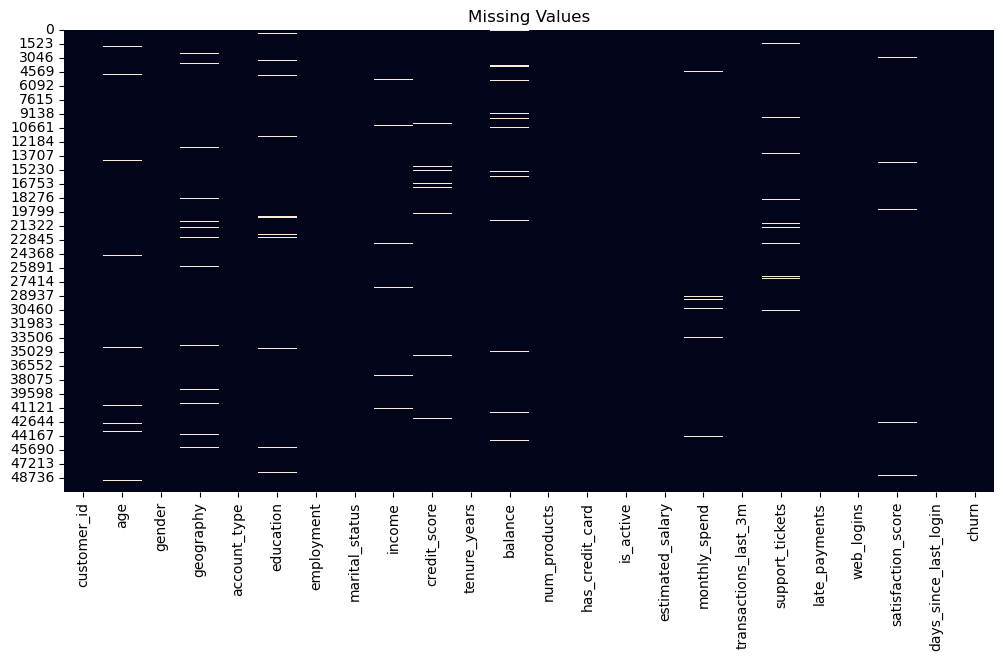

In [55]:
#5. Check missing values
df.isnull().sum()

# #for percentages
missing_percentage = (df.isnull().sum() / len(df)) * 100
missing_percentage.sort_values(ascending=False)

# for visualization
plt.figure(figsize=(12,6))
sns.heatmap(df.isnull(),cbar=False)
plt.title("Missing Values")
plt.show()#identify which cols contain missing vals

In [56]:
#6. Find duplicate rows and drop them
df.duplicated().sum()
df[df.duplicated()]
df = df.drop_duplicates()
df.duplicated().sum()

0

In [57]:
#7. Check invalid values
df["age"].describe()
df[(df["age"] < 18) | (df["age"] > 80)]
df.loc[(df["age"] <18) | (df["age"] >80),"age"] = np.nan
df["age"].isnull().sum()

1030

In [58]:
# 9. Check credit score 
# Valid credit scores are generally between 300 and 850.
df["credit_score"].describe()
df[
    (df["credit_score"] < 300) |
    (df["credit_score"] > 850)
]

#replacing with null values
df.loc[
    (df["credit_score"] < 300) |
    (df["credit_score"] > 850),
    "credit_score"
] = np.nan

df["credit_score"].isnull().sum()

1030

In [59]:
# 10. Check income
df["income"].describe()
df[df["income"] < 0]
df.loc[df["income"] < 0, "income"] = np.nan
df["income"].isnull().sum()

1020

In [60]:
# 11. Check satisfaction score
# Your satisfaction score should be between 1 and 10.

df["satisfaction_score"].describe()
# df["satisfaction_score"].isnull().sum()
df[
    (df["satisfaction_score"] < 1) |
    (df["satisfaction_score"] > 10)
]

df.loc[
    (df["satisfaction_score"] < 1) |
    (df["satisfaction_score"] > 10),
    "satisfaction_score"
] = np.nan

df["satisfaction_score"].isnull().sum()

1028

In [61]:
# 12. Clean categorical values
df["gender"].value_counts()

df["gender"] = df["gender"].replace({
    "male": "Male",
    "M": "Male",
    "MALE": "Male"
})

df["gender"].value_counts()

gender
Male      24495
Female    24474
Other      1031
Name: count, dtype: int64

In [62]:
# 13. Clean account type
df["account_type"].value_counts(dropna=False)
df["account_type"] = df["account_type"].str.strip()
df["account_type"] = df["account_type"].replace({
    "saving": "Savings",
    "SAVINGS": "Savings",
    "premium": "Premium"
})
df["account_type"].value_counts(dropna=False)

account_type
Savings    29055
Current    13498
Premium     7447
Name: count, dtype: int64

In [63]:
# 14. Clean employment
df["employment"].value_counts(dropna=False)

df["employment"] = df["employment"].str.strip()

df["employment"] = df["employment"].replace({
    "salaried": "Salaried",
    "Self Employed": "Self-employed",
    "BUSINESS": "Business"
})
df["employment"].value_counts()

employment
Salaried         24222
Self-employed     9015
Business          7873
Student           4977
Retired           3913
Name: count, dtype: int64

In [64]:
# df["geography"].value_counts(dropna=False)
# df["education"].value_counts(dropna=False)
# df["marital_status"].value_counts(dropna=False)

In [65]:
print(df.info())
print(df.describe(include="int64"))
print(df.describe(include="float64"))

<class 'pandas.core.frame.DataFrame'>
Index: 50000 entries, 0 to 50249
Data columns (total 24 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   customer_id            50000 non-null  int64  
 1   age                    48970 non-null  float64
 2   gender                 50000 non-null  object 
 3   geography              49000 non-null  object 
 4   account_type           50000 non-null  object 
 5   education              49000 non-null  object 
 6   employment             50000 non-null  object 
 7   marital_status         50000 non-null  object 
 8   income                 48980 non-null  float64
 9   credit_score           48970 non-null  float64
 10  tenure_years           50000 non-null  float64
 11  balance                49000 non-null  float64
 12  num_products           50000 non-null  int64  
 13  has_credit_card        50000 non-null  int64  
 14  is_active              50000 non-null  int64  
 15  estimat

In [66]:
# 15. Detect outliers
numerical_columns = df.select_dtypes(include=np.number).columns
df[numerical_columns].describe()

,customer_id,age,income,credit_score,tenure_years,balance,num_products,has_credit_card,is_active,estimated_salary,monthly_spend,transactions_last_3m,support_tickets,late_payments,web_logins,satisfaction_score,days_since_last_login,churn
count,5.000000e+04,48970.000000,4.898000e+04,48970.000000,50000.000000,49000.000000,50000.00000,50000.000000,50000.000000,50000.000000,49000.000000,50000.000000,49000.000000,50000.000000,50000.000000,48972.000000,50000.000000,50000.00000
mean,1.025000e+06,38.150888,6.568846e+04,679.523423,3.428586,15359.879619,1.63984,0.751300,0.517080,56689.034499,2118.116500,18.031280,1.505592,0.795460,9.013960,5.504717,26.391880,0.10614
std,1.443390e+04,10.691996,1.467641e+05,74.514224,3.278132,10339.631512,0.71572,0.432264,0.499713,29709.078865,1335.100916,4.247887,1.237921,0.893487,2.992635,2.871069,17.863778,0.30802
min,1.000001e+06,18.000000,1.500000e+04,319.000000,0.000000,71.810000,1.00000,0.000000,0.000000,12000.000000,50.000000,4.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.00000
25%,1.012501e+06,31.000000,3.777225e+04,629.000000,1.000000,7749.057500,1.00000,1.000000,0.000000,35766.110000,1136.647500,15.000000,1.000000,0.000000,7.000000,3.000000,13.000000,0.00000
50%,1.025000e+06,38.000000,5.458871e+04,680.000000,2.400000,13188.985000,2.00000,1.000000,1.000000,49957.720000,1847.740000,18.000000,1.000000,1.000000,9.000000,6.000000,23.000000,0.00000
75%,1.037500e+06,45.000000,7.953979e+04,731.000000,4.800000,20549.920000,2.00000,1.000000,1.000000,70277.967500,2815.460000,21.000000,2.000000,1.000000,11.000000,8.000000,35.000000,0.00000
max,1.050000e+06,80.000000,9.999999e+06,850.000000,15.000000,100000.000000,4.00000,1.000000,1.000000,200000.000000,13059.480000,39.000000,9.000000,6.000000,24.000000,10.000000,179.000000,1.00000


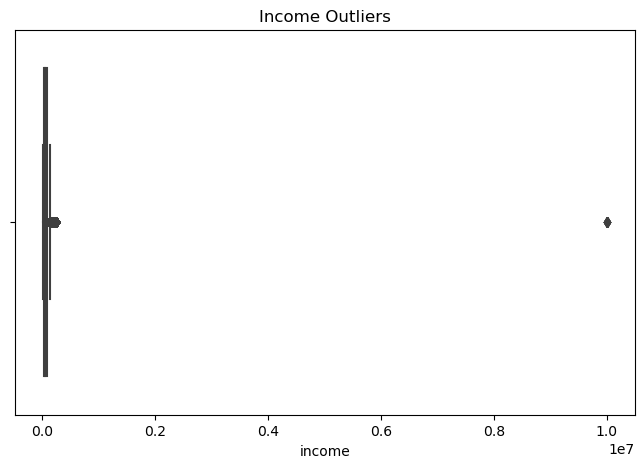

In [67]:
plt.figure(figsize=(8,5))
sns.boxplot(x=df["income"])
plt.title("Income Outliers")
plt.show()

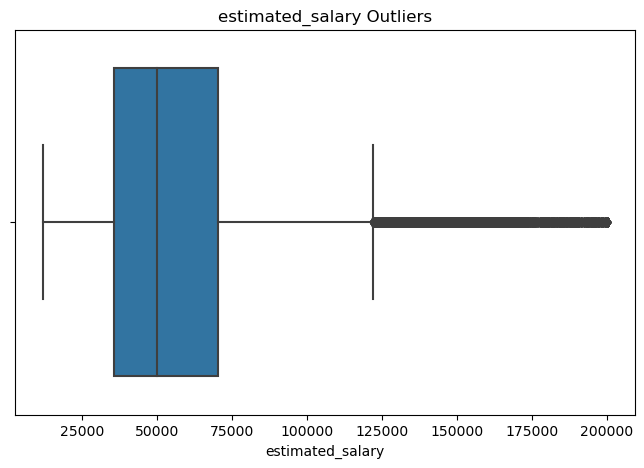

In [68]:
plt.figure(figsize=(8,5))
sns.boxplot(x=df["estimated_salary"])
plt.title("estimated_salary Outliers")
plt.show()

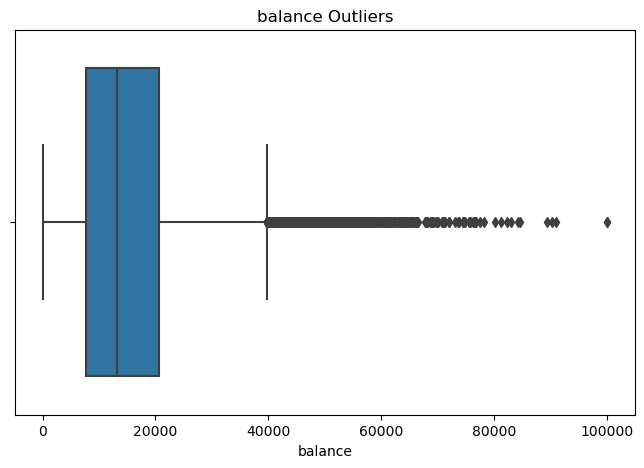

In [69]:
plt.figure(figsize=(8,5))
sns.boxplot(x=df["balance"])
plt.title("balance Outliers")
plt.show()

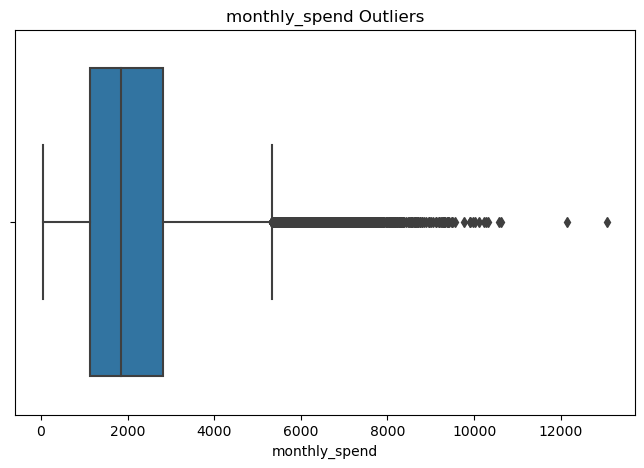

In [70]:
plt.figure(figsize=(8,5))
sns.boxplot(x=df["monthly_spend"])
plt.title("monthly_spend Outliers")
plt.show()

In [71]:
# plt.figure(figsize=(8,5))
# sns.boxplot(x=df["age"])
# plt.title("age Outliers")
# plt.show()

In [72]:
# 16. Understand the IQR method
# A common method for detecting outliers is IQR.

def find_outliers(df,column):
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    
    IQR = Q3 - Q1
    
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    
    return df[
        (df[column]<lower) | (df[column]>upper)
    ]

find_outliers(df,"income")

,customer_id,age,gender,geography,account_type,education,employment,marital_status,income,credit_score,...,is_active,estimated_salary,monthly_spend,transactions_last_3m,support_tickets,late_payments,web_logins,satisfaction_score,days_since_last_login,churn
49,1001004,45.0,Male,Chennai,Current,Graduate,Self-employed,Married,183985.35,660.0,...,1,64951.18,2431.65,12,3.0,1,7,6.0,8,0
78,1018918,43.0,Male,Bengaluru,Current,High School,Business,Single,144481.01,642.0,...,1,47427.93,1403.51,15,1.0,0,2,5.0,24,0
98,1049383,27.0,Female,Pune,Savings,Graduate,Retired,Married,159319.77,715.0,...,0,41035.05,1742.58,22,1.0,0,11,2.0,2,0
146,1033948,23.0,Female,Hyderabad,Savings,Graduate,Salaried,Married,170093.20,677.0,...,1,46278.80,2264.80,15,0.0,2,6,3.0,17,0
165,1015727,20.0,Male,Chennai,Current,Postgraduate,Salaried,Single,201401.27,539.0,...,1,50508.71,4678.57,21,2.0,0,11,10.0,7,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
50208,1021778,43.0,Male,Bengaluru,Savings,Postgraduate,Salaried,Married,144148.13,567.0,...,0,67219.12,133.71,16,1.0,0,13,8.0,79,0
50224,1025659,27.0,Male,Mumbai,Premium,High School,Business,Married,234126.81,761.0,...,0,107148.94,1713.07,16,NaN,1,7,3.0,35,0
50229,1019770,51.0,Male,Hyderabad,Savings,Postgraduate,Business,Married,149949.31,589.0,...,1,164214.36,2822.10,13,1.0,2,10,6.0,22,1
50231,1039189,21.0,Female,Delhi,Savings,High School,Student,Divorced,209554.96,759.0,...,0,16788.46,4195.64,21,3.0,0,1,NaN,10,1


In [73]:
#17. Don't blindly delete every outlier
#Not every outlier is an error.
# So distinguish between:

# Invalid values → fix/remove

# and

# Legitimate extreme values → potentially keep

In [74]:
# 18. Separate X and y
X = df.drop("churn",axis=1)
y = df["churn"]

In [75]:
X.shape

(50000, 23)

In [76]:
y.shape

(50000,)

In [77]:
# 19. What about customer_id?
# customer_id shouldn't be used as a predictive feature.
#doesn't tell the model anything meaningful about whether the customer will churn.
X = X.drop("customer_id",axis=1)

In [78]:
# 20. Identify numerical and categorical columns
numeric_features=X.select_dtypes(include=["int64","float64"]).columns
categorical_features=X.select_dtypes(include=["object"]).columns

print("Numerical:")
print(numeric_features)

print("\nCategorical:")
print(categorical_features)

Numerical:
Index(['age', 'income', 'credit_score', 'tenure_years', 'balance',
       'num_products', 'has_credit_card', 'is_active', 'estimated_salary',
       'monthly_spend', 'transactions_last_3m', 'support_tickets',
       'late_payments', 'web_logins', 'satisfaction_score',
       'days_since_last_login'],
      dtype='object')

Categorical:
Index(['gender', 'geography', 'account_type', 'education', 'employment',
       'marital_status'],
      dtype='object')


In [79]:
# 21. Train-test split
# stratify=y is particularly useful because your target is imbalanced.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
#     It preserves approximately the same target-class proportions
#     in training and testing data.
)

In [80]:
# 22. Missing-value treatment(Preprocessing pipeline)
# Numerical columns - Median imputation.
# Categorical columns - Most-frequent value

numeric_transformer = Pipeline(
    steps=[
        ("imputer",SimpleImputer(strategy="median")),
        ("scaler",StandardScaler())
    ]
)

categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]
)

In [81]:
# Income has a much larger numerical scale.
# StandardScaler converts features approximately to:
#     mean = 0
# standard deviation = 1
# This prevents large-scale features from dominating distance/optimization-based models.

In [82]:
# 24. Create preprocessing pipeline
preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            numeric_transformer,
            numeric_features
        ),
        (
            "cat",
            categorical_transformer,
            categorical_features
        )
    ]
)

# This pipeline will automatically:

# Fill numerical missing values
# Scale numerical values
# Fill categorical missing values
# One-hot encode categorical values

In [83]:
# 25. Cross-validation setup
# Your training data is divided into five folds. Each round trains on 
# four folds and validates on the remaining fold. Every fold serves as 
# the validation fold once.

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [84]:
# # 25. Model 1 — Logistic Regression

# logistic_model=Pipeline(
#     steps=[
#         ("preprocessor", preprocessor),
#         ("classifier",LogisticRegression(
#             max_iter=1000,
#             class_weight="balanced"
#         ))
#     ]
# )

# # Train,predict and probability

In [85]:
# logistic_model.fit(X_train,y_train)

In [86]:
# y_pred_lr = logistic_model.predict(X_test)
# y_prob_lr = logistic_model.predict_proba(X_test)[:, 1]

In [87]:
# # 26. Evaluate Logistic Regression
# print(accuracy_score(y_test,y_pred_lr))
# print(precision_score(y_test,y_pred_lr))
# print(recall_score(y_test,y_pred_lr))
# print(f1_score(y_test,y_pred_lr))
# print(roc_auc_score(y_test,y_prob_lr))
# print(classification_report(y_test, y_pred_lr))#complete report

In [88]:
# # 27. Confusion matrix
# cm = confusion_matrix(y_test, y_pred_lr)

# sns.heatmap(
#     cm,
#     annot=True,
#     fmt="d",
#     cmap="Blues"
# )

# plt.xlabel("Predicted")
# plt.ylabel("Actual")
# plt.title("Logistic Regression Confusion Matrix")

# plt.show()
# print(cm)

In [89]:
# # 28. Model 2 — Decision Tree
# # Because without a depth limit, a decision tree can become extremely complex and overfit.

# decision_tree = Pipeline(
#     steps=[
#         ("preprocessor", preprocessor),
#         ("classifier", DecisionTreeClassifier(
#             criterion="gini",
#             max_depth=8,
#             min_samples_split=10,
#             min_samples_leaf=5,
#             random_state=42,
#             class_weight="balanced"
#         ))
#     ]
# )

# # Train,predict,probability,evaluate
# decision_tree.fit(X_train, y_train)

In [90]:
# y_pred_dt = decision_tree.predict(X_test)

In [91]:
# y_prob_dt = decision_tree.predict_proba(X_test)[:, 1]

In [92]:
# print("Accuracy:", accuracy_score(y_test, y_pred_dt))
# print("Precision:", precision_score(y_test, y_pred_dt))
# print("Recall:", recall_score(y_test, y_pred_dt))
# print("F1:", f1_score(y_test, y_pred_dt))
# print("ROC-AUC:", roc_auc_score(y_test, y_prob_dt)) 

# cm = confusion_matrix(y_test, y_pred_dt)
# cm

In [93]:
# # 29. Model 3 — Random Forest

# random_forest = Pipeline(
#     steps=[
#         ("preprocessor",preprocessor),
#         ("classifier",RandomForestClassifier(
#             n_estimators=200,
#             criterion="gini",
#             min_samples_split=10,
#             min_samples_leaf=5,
#             max_features="sqrt",
#             class_weight="balanced",
#             max_depth=10,
#             random_state=42,
#             n_jobs=-1))
#     ]
# )

# #Train,predict,probability,evaluate

# random_forest.fit(X_train, y_train)

In [94]:
# y_pred_rf = random_forest.predict(X_test)

In [95]:
# y_prob_rf = random_forest.predict_proba(X_test)[:, 1]

In [96]:
# print("Accuracy:", accuracy_score(y_test, y_pred_rf))
#  print("Precision:", precision_score(y_test, y_pred_rf))
# print("Recall:", recall_score(y_test, y_pred_rf))
# print("F1:", f1_score(y_test, y_pred_rf))
# print("ROC-AUC:", roc_auc_score(y_test, y_prob_rf)) 
# print(confusion_matrix(y_test, y_pred_rf))

In [97]:
# # 30. Model 4 — SVM

# svm_model = Pipeline([
#     ("preprocessor", preprocessor),
#     ("model", LinearSVC(
#          C=1.0,
#         class_weight="balanced",
#         max_iter=10000,
#         dual="auto",
#         random_state=42
#     ))
# ])
# # Train,predict,probability,evaluate

In [98]:
# svm_model.fit(X_train, y_train)

In [99]:
# y_pred_svm = svm_model.predict(X_test)

In [100]:
# y_score_svm = svm_model.decision_function(X_test)

In [101]:
# print("Accuracy:", accuracy_score(y_test, y_pred_svm))
# print("Precision:", precision_score(y_test, y_pred_svm))
# print("Recall:", recall_score(y_test, y_pred_svm))
# print("F1:", f1_score(y_test, y_pred_svm))
# print("ROC-AUC:", roc_auc_score(y_test, y_score_svm))
# print(confusion_matrix(y_test, y_pred_svm))

In [102]:
# SVC(
#     kernel="rbf",
#     probability=True,
#     random_state=42,
#     cache_size=2000
# )

In [103]:
# ### KNN Model
# knn_model = Pipeline(
#     steps=[
#         ("preprocessor", preprocessor),
#         ("classifier", KNeighborsClassifier(
#             n_neighbors=5,
#             weights="distance",
#             metric="minkowski",
#             p=2,
#             n_jobs=1
#         ))
#     ]
# )


In [104]:
# # Train the model
# knn_model.fit(X_train, y_train)

In [105]:
# # Predictions
# y_pred_knn = knn_model.predict(X_test)
# y_prob_knn = knn_model.predict_proba(X_test)[:, 1]

In [106]:
# # Evaluate the model
# print("KNN Results")
# print("Accuracy:", accuracy_score(y_test, y_pred_knn))
# print("Precision:", precision_score(y_test, y_pred_knn, zero_division=0))
# print("Recall:", recall_score(y_test, y_pred_knn, zero_division=0))
# print("F1 Score:", f1_score(y_test, y_pred_knn, zero_division=0))
# print("ROC-AUC:", roc_auc_score(y_test, y_prob_knn))
# print("Confusion Matrix:", confusion_matrix(y_test,y_pred_knn))

In [107]:
# # 31. Create one comparison table

# results = pd.DataFrame({
#     "Model": [
#         "Logistic Regression",
#         "Decision Tree",
#         "Random Forest",
#         "SVM",
#         "KNN"
#     ],

#     "Accuracy": [
#         accuracy_score(y_test, y_pred_lr),
#         accuracy_score(y_test, y_pred_dt),
#         accuracy_score(y_test, y_pred_rf),
#         accuracy_score(y_test, y_pred_svm),
#         accuracy_score(y_test, y_pred_knn)
#     ],

#     "Precision": [
#         precision_score(y_test, y_pred_lr),
#         precision_score(y_test, y_pred_dt),
#         precision_score(y_test, y_pred_rf),
#         precision_score(y_test, y_pred_svm),
#         precision_score(y_test, y_pred_knn)
#     ],

#     "Recall": [
#         recall_score(y_test, y_pred_lr),
#         recall_score(y_test, y_pred_dt),
#         recall_score(y_test, y_pred_rf),
#         recall_score(y_test, y_pred_svm),
#         recall_score(y_test, y_pred_knn)
#     ],

#     "F1 Score": [
#         f1_score(y_test, y_pred_lr),
#         f1_score(y_test, y_pred_dt),
#         f1_score(y_test, y_pred_rf),
#         f1_score(y_test, y_pred_svm),
#         f1_score(y_test, y_pred_knn)
#     ],

#     "ROC-AUC": [
#         roc_auc_score(y_test, y_prob_lr),
#         roc_auc_score(y_test, y_prob_dt),
#         roc_auc_score(y_test, y_prob_rf),
#         roc_auc_score(y_test, y_score_svm),
#         roc_auc_score(y_test, y_prob_knn)
#     ]
# })

# results

In [108]:
# #32. Plot model comparison
# results.set_index("Model")[[
#     "Accuracy",
#     "Precision",
#     "Recall",
#     "F1 Score",
#     "ROC-AUC"
# ]].plot(
#     kind="bar",
#     figsize=(12,6)
# )

# plt.title("Model Performance Comparison")
# plt.ylabel("Score")
# plt.xticks(rotation=20)
# plt.ylim(0, 1)
# plt.legend(loc="lower right")

# plt.show()

In [109]:
# #33. ROC curves
# fpr_lr, tpr_lr, _ = roc_curve(y_test, y_prob_lr)
# fpr_dt, tpr_dt, _ = roc_curve(y_test, y_prob_dt)
# fpr_rf, tpr_rf, _ = roc_curve(y_test, y_prob_rf)
# fpr_svm, tpr_svm, _ = roc_curve(y_test, y_score_svm)
# fpr_knn, tpr_knn, _ = roc_curve(y_test, y_prob_knn)

In [110]:
# plt.figure(figsize=(10,7))

# plt.plot(
#     fpr_lr,
#     tpr_lr,
#     label="Logistic Regression"
# )

# plt.plot(
#     fpr_dt,
#     tpr_dt,
#     label="Decision Tree"
# )

# plt.plot(
#     fpr_rf,
#     tpr_rf,
#     label="Random Forest"
# )

# plt.plot(
#     fpr_svm,
#     tpr_svm,
#     label="SVM"
# )

# plt.plot(
#     fpr_knn,
#     tpr_knn,
#     label="KNN"
# )

# plt.plot(
#     [0, 1],
#     [0, 1],
#     linestyle="--"
# )

# plt.xlabel("False Positive Rate")
# plt.ylabel("True Positive Rate")

# plt.title("ROC Curve Comparison")

# plt.legend()

# plt.show()

In [111]:
# In imbalanced classification, accuracy alone can be misleading.
# The appropriate model depends on the problem's objective, and 
# metrics such as recall, F1-score, and ROC-AUC help provide a more
# complete evaluation.

In [112]:
# 26: Automatically tune all five models

# Create model pipelines for automatic tuning

tuning_models = {
    "Logistic Regression": Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(
            max_iter=2000,
            class_weight="balanced",
            random_state=42
        ))
    ]),

    "Decision Tree": Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", DecisionTreeClassifier(
            class_weight="balanced",
            random_state=42
        ))
    ]),

    "Random Forest": Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(
            class_weight="balanced",
            random_state=42,
            n_jobs=1
        ))
    ]),

    "SVM": Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", LinearSVC(
            class_weight="balanced",
            max_iter=15000,
            dual="auto",
            random_state=42
        ))
    ]),

    "KNN": Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", KNeighborsClassifier(
            n_jobs=1
        ))
    ])
}


In [113]:
# 27. Hyperparameter search spaces

param_grids = {
    "Logistic Regression": {
        "classifier__C": [0.01, 0.1, 1, 10],
        "classifier__solver": ["lbfgs"]
    },

    "Decision Tree": {
        "classifier__criterion": ["gini", "entropy"],
        "classifier__max_depth": [5, 8, 12, 16, None],
        "classifier__min_samples_split": [10, 20, 50],
        "classifier__min_samples_leaf": [5, 10, 20]
    },

    "SVM": {
        "classifier__C": [0.01, 0.1, 1, 10]
    },

    "KNN": {
        "classifier__n_neighbors": [3, 5, 7, 11, 15],
        "classifier__weights": ["uniform", "distance"],
        "classifier__p": [1, 2]
    }
}

In [114]:
# 28. Random Forest search space

rf_param_distributions = {
    "classifier__n_estimators": [100, 200, 300],
    "classifier__max_depth": [5, 8, 10, 15, None],
    "classifier__min_samples_split": [10, 20, 50],
    "classifier__min_samples_leaf": [5, 10, 20],
    "classifier__max_features": ["sqrt", "log2"],
    "classifier__criterion": ["gini", "entropy"]
}

In [115]:
# 29. Run GridSearchCV and RandomizedSearchCV(Run automatic search)

best_models = {}
search_results = []

for name, pipeline in tuning_models.items():

    print(f"\nTuning {name}...")

    if name == "Random Forest":

        search = RandomizedSearchCV(
            estimator=pipeline,
            param_distributions=rf_param_distributions,
            n_iter=10,
            scoring="f1",
            cv=cv,
            random_state=42,
            n_jobs=-1,
            verbose=1, #Prints progress information while the search runs.
            refit=True #After finding the best hyperparameter combination, 
#            fits that configuration again on the entire training dataset.
        )

    else:

        search = GridSearchCV(
            estimator=pipeline,
            param_grid=param_grids[name],
            scoring="f1",
            cv=cv,
            n_jobs=-1,
            verbose=1,
            refit=True
        )

    search.fit(X_train, y_train)
#     It tries the sampled hyperparameter combinations, evaluates 
#     them through cross-validation, and selects the best combination
#     according to your scoring metric.

    best_models[name] = search.best_estimator_

    search_results.append({
        "Model": name,
        "Best CV F1": search.best_score_,
        "Best Parameters": search.best_params_
    })

    print("Best CV F1:", search.best_score_)
    print("Best Parameters:", search.best_params_)


Tuning Logistic Regression...
Fitting 5 folds for each of 4 candidates, totalling 20 fits
Best CV F1: 0.2903402182342374
Best Parameters: {'classifier__C': 0.01, 'classifier__solver': 'lbfgs'}

Tuning Decision Tree...
Fitting 5 folds for each of 90 candidates, totalling 450 fits
Best CV F1: 0.2579319147111415
Best Parameters: {'classifier__criterion': 'entropy', 'classifier__max_depth': 5, 'classifier__min_samples_leaf': 20, 'classifier__min_samples_split': 10}

Tuning Random Forest...
Fitting 5 folds for each of 10 candidates, totalling 50 fits
Best CV F1: 0.3012650727108097
Best Parameters: {'classifier__n_estimators': 200, 'classifier__min_samples_split': 20, 'classifier__min_samples_leaf': 10, 'classifier__max_features': 'log2', 'classifier__max_depth': 10, 'classifier__criterion': 'entropy'}

Tuning SVM...
Fitting 5 folds for each of 4 candidates, totalling 20 fits
Best CV F1: 0.2891658433392329
Best Parameters: {'classifier__C': 0.1}

Tuning KNN...
Fitting 5 folds for each of 20

In [116]:
# 30. Compare cross-validation results(view best hyper params found)

cv_results_df = pd.DataFrame(search_results)

cv_results_df = cv_results_df.sort_values(
    by="Best CV F1",
    ascending=False
)

cv_results_df

,Model,Best CV F1,Best Parameters
2,Random Forest,0.301265,"{'classifier__n_estimators': 200, 'classifier_..."
0,Logistic Regression,0.290340,"{'classifier__C': 0.01, 'classifier__solver': ..."
3,SVM,0.289166,{'classifier__C': 0.1}
1,Decision Tree,0.257932,"{'classifier__criterion': 'entropy', 'classifi..."
4,KNN,0.091996,"{'classifier__n_neighbors': 3, 'classifier__p'..."


In [117]:
# You can also inspect an individual result:
best_models["Logistic Regression"]

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  Index(['age', 'income', 'credit_score', 'tenure_years', 'balance',
       'num_products', 'has_credit_card', 'is_active', 'estimated_salary',
       'monthly_spend', 'transactions_last_3m', 'support_tickets',
       'late...
       'days_since_last_login'],
      dtype='object')),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  Index(['gender', 'geography', 'account_type', 'education', 'employment',
       'marital_status'],
      dtype='object'))])),
                ('classifier',
                 LogisticRegression(C=0.01, class_weight='balanced',
                                    max_iter=2000, random_state=42))])

In [118]:
# Or retrieve its best parameters directly:
cv_results_df.loc[
    cv_results_df["Model"] == "Logistic Regression",
    "Best Parameters"
].iloc[0]

{'classifier__C': 0.01, 'classifier__solver': 'lbfgs'}

In [119]:
# 31. Final evaluation of tuned models on test set

tuned_results = []
tuned_predictions = {}
tuned_scores = {}

for name, model in best_models.items():

    # Predict classes
    y_pred = model.predict(X_test)

    # Get scores for ROC-AUC
    if name == "SVM":
        y_score = model.decision_function(X_test)
    else:
        y_score = model.predict_proba(X_test)[:, 1]

    tuned_predictions[name] = y_pred
    tuned_scores[name] = y_score

    tuned_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, y_pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, y_score)
    })

tuned_comparison = pd.DataFrame(tuned_results)

tuned_comparison.sort_values(
    by="F1 Score",
    ascending=False
)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
2,Random Forest,0.7647,0.211349,0.445806,0.286754,0.703789
0,Logistic Regression,0.6539,0.183043,0.653157,0.285950,0.714600
3,SVM,0.6513,0.182128,0.655042,0.285011,0.714502
1,Decision Tree,0.6504,0.164878,0.564562,0.255219,0.655385
4,KNN,0.8740,0.169435,0.048068,0.074890,0.555853


In [120]:
#Remember: the best cross-validation model isn't guaranteed to perform
# best on the test set. That is why we keep the test set separate and 
# evaluate the selected models on it only after tuning.

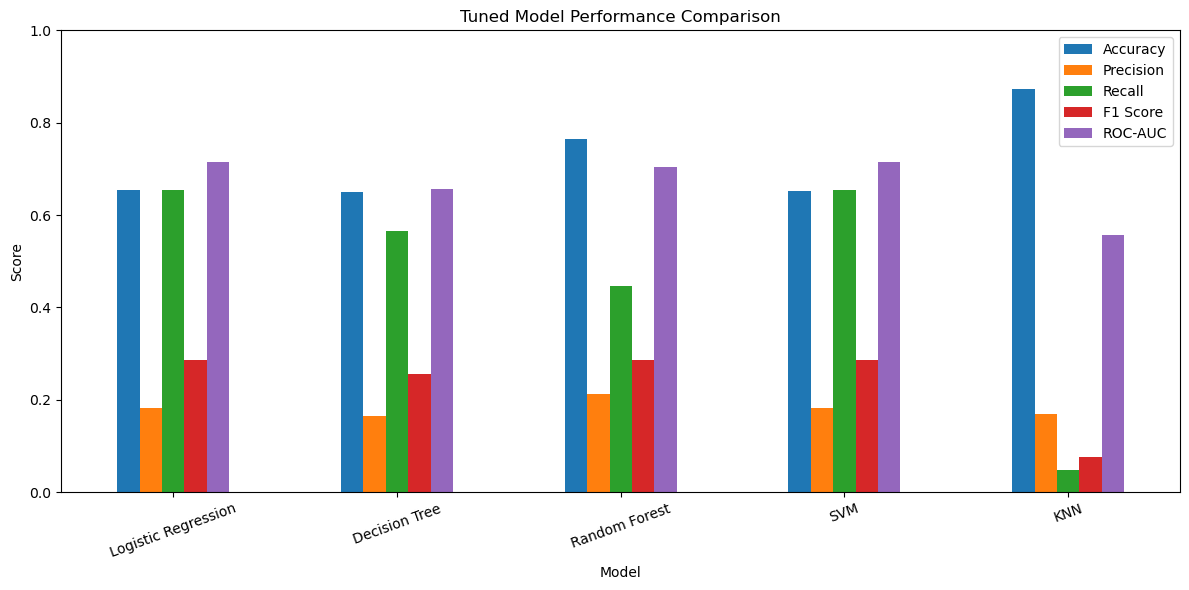

In [121]:
# 32. Compare tuned models(Plot model comparision)

tuned_comparison.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"]
].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Tuned Model Performance Comparison")
plt.ylabel("Score")
plt.xticks(rotation=20)
plt.ylim(0, 1)
# plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

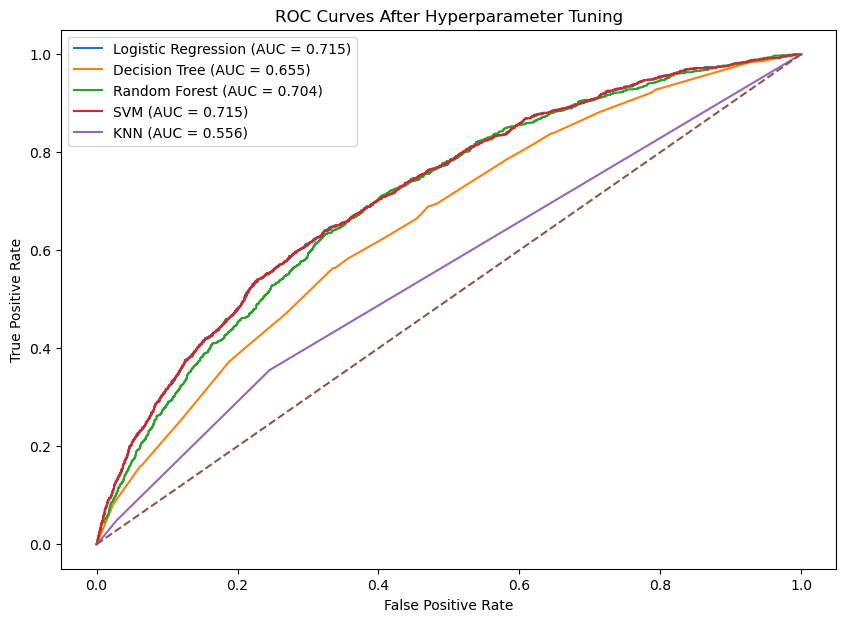

In [122]:
# 33. ROC curves for tuned models

plt.figure(figsize=(10, 7))

for name, y_score in tuned_scores.items():

    fpr, tpr, thresholds = roc_curve(y_test, y_score)

    auc = roc_auc_score(y_test, y_score)

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC = {auc:.3f})"
    )

plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves After Hyperparameter Tuning")
plt.legend()
plt.show()

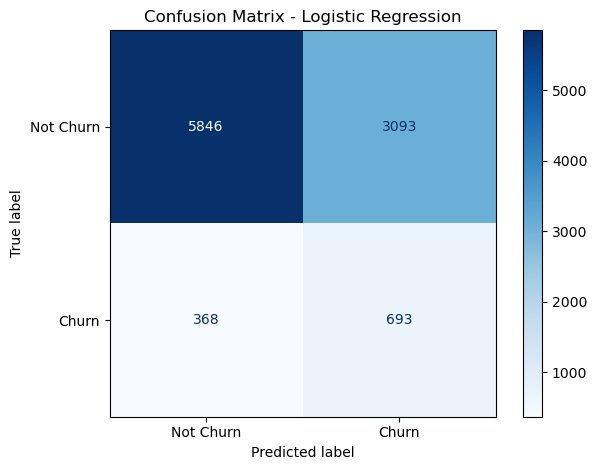

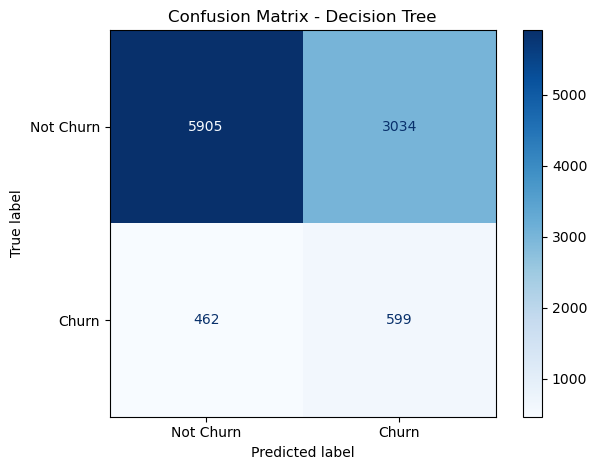

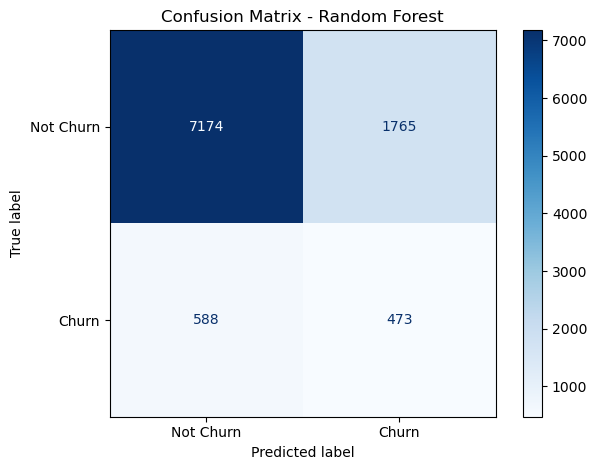

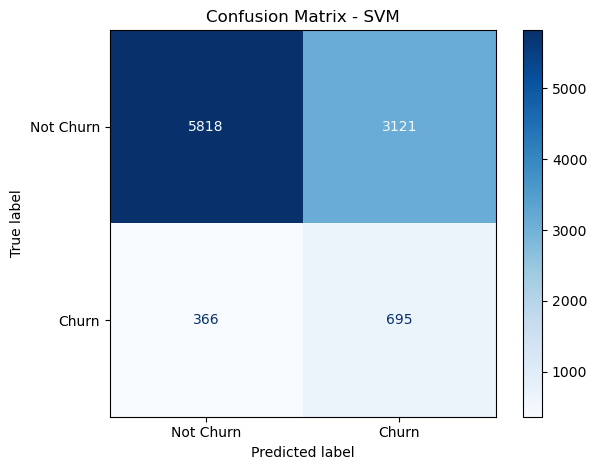

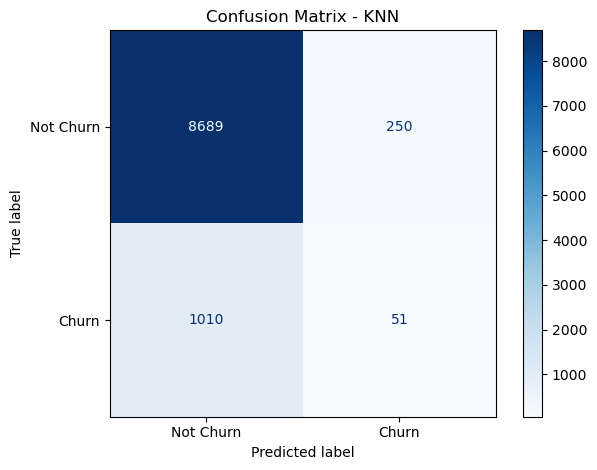

In [123]:
# 34.Confusion Matrix shows how many predictions were correct
# and incorrect for each class.

#You should not decide based on the confusion matrix alone. You need 
# to consider what kind of mistakes your model makes and what your 
# project is trying to achieve.

for name, model in best_models.items():

    # Predict using the tuned model
    y_pred = model.predict(X_test)

    # Calculate confusion matrix
    cm = confusion_matrix(y_test, y_pred)

    # Display confusion matrix
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Not Churn", "Churn"]
    )

    disp.plot(cmap="Blues", values_format="d")

    plt.title(f"Confusion Matrix - {name}")
    plt.tight_layout()
    plt.show()

In [124]:
# 35. Classification Report for all tuned models

from sklearn.metrics import classification_report

for name, model in best_models.items():

    y_pred = tuned_predictions[name]

    print("\n" + "=" * 65)
    print(f"CLASSIFICATION REPORT - {name}")
    print("=" * 65)

    print(
        classification_report(
            y_test,
            y_pred,
            target_names=["Not Churn", "Churn"],
            digits=4,
            zero_division=0
        )
    )


CLASSIFICATION REPORT - Logistic Regression
              precision    recall  f1-score   support

   Not Churn     0.9408    0.6540    0.7716      8939
       Churn     0.1830    0.6532    0.2860      1061

    accuracy                         0.6539     10000
   macro avg     0.5619    0.6536    0.5288     10000
weighted avg     0.8604    0.6539    0.7201     10000


CLASSIFICATION REPORT - Decision Tree
              precision    recall  f1-score   support

   Not Churn     0.9274    0.6606    0.7716      8939
       Churn     0.1649    0.5646    0.2552      1061

    accuracy                         0.6504     10000
   macro avg     0.5462    0.6126    0.5134     10000
weighted avg     0.8465    0.6504    0.7168     10000


CLASSIFICATION REPORT - Random Forest
              precision    recall  f1-score   support

   Not Churn     0.9242    0.8026    0.8591      8939
       Churn     0.2113    0.4458    0.2868      1061

    accuracy                         0.7647     10000
   ma

                       Feature  Importance
14     num__satisfaction_score    0.157829
3            num__tenure_years    0.114535
2            num__credit_score    0.108890
0                     num__age    0.055449
4                 num__balance    0.055392
15  num__days_since_last_login    0.053907
7               num__is_active    0.048529
8        num__estimated_salary    0.048142
1                  num__income    0.047774
9           num__monthly_spend    0.046605
10   num__transactions_last_3m    0.045858
13             num__web_logins    0.028981
5            num__num_products    0.025512
12          num__late_payments    0.022629
11        num__support_tickets    0.019113


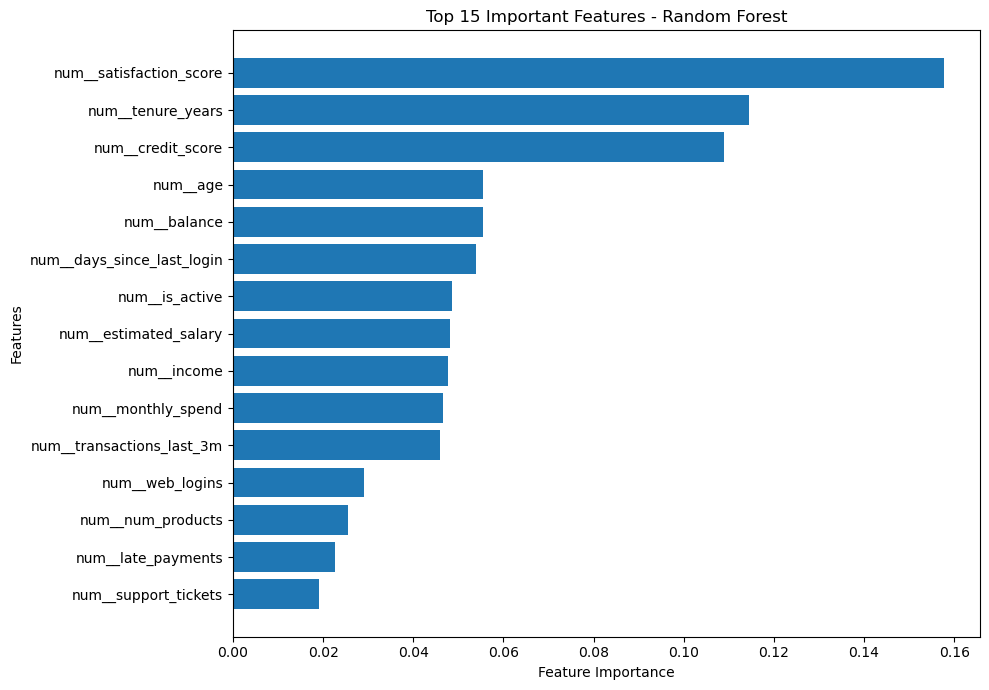

In [125]:
# 36. Feature Importance - Random Forest

import pandas as pd
import matplotlib.pyplot as plt

# Get the best tuned Random Forest pipeline
rf_pipeline = best_models["Random Forest"]

# Extract the fitted preprocessor
fitted_preprocessor = rf_pipeline.named_steps["preprocessor"]

# Extract the fitted Random Forest classifier
rf_model = rf_pipeline.named_steps["classifier"]

# Get feature names after preprocessing
feature_names = fitted_preprocessor.get_feature_names_out()

# Get feature importance values
importance = rf_model.feature_importances_

# Create DataFrame
feature_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
})

# Sort by importance
feature_importance_df = feature_importance_df.sort_values(
    by="Importance",
    ascending=False
)

# Display top 15 features
print(feature_importance_df.head(15))

# Visualize top 15 features
top_features = feature_importance_df.head(15).sort_values(
    by="Importance",
    ascending=True
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Features")
plt.title("Top 15 Important Features - Random Forest")

plt.tight_layout()
plt.show()

In [126]:
# # 8. How do you choose between F1-score, recall, and ROC-AUC?

# # This is particularly important for your churn project because 
# roughly 10% of customers churn.
# # Scoring option	When to use it
# # scoring="f1"	You want a balance between finding churners and 
# avoiding too many false alarms.
# # scoring="recall"	Missing a customer who will churn is especially 
# costly.
# # scoring="roc_auc"	You want to compare how well models rank churners 
# above non-churners across thresholds.

# # For your current learning objective, I recommend starting with 
# F1-score, as in the code above. You can later run another search 
# using recall to see how the results change.

# # One more point: the default prediction threshold is generally 0.5 
# for probability-based classifiers. Hyperparameter tuning does not 
# automatically find the ideal classification threshold. Threshold 
# tuning is a separate step you can learn afterward.

In [127]:
# saving best performed model pipeline into joblib

import joblib
import os

os.makedirs("model", exist_ok=True)

best_model = best_models["Random Forest"]

joblib.dump(best_model, "model/churn_pipeline.joblib")

print("Model saved successfully!")

Model saved successfully!


In [128]:
#Step 2: Verify that your model was saved

import os

print(os.path.exists("model/churn_pipeline.joblib"))

True


In [129]:
#Step 3: Test loading your saved model

import joblib

loaded_model = joblib.load("model/churn_pipeline.joblib")

print("Model loaded successfully!")

Model loaded successfully!


In [130]:
sample_data = X_test.head(5)

predictions = loaded_model.predict(sample_data)

print(predictions)

[1 1 0 0 0]
